In [69]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
!pip install imbalanced-learn

**PARTIE 1:**

Téléchargement du dataset

In [ ]:

df=pd.read_csv('titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.shape

(891, 12)

In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


**X: Separation du donnees**

In [ ]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print ("training set:",X_train.shape,y_train.shape)
print ("testing set:",X_test.shape,y_test.shape)

training set: (712, 11) (712,)
testing set: (179, 11) (179,)


**Partie 2 : Nettoyage des Données**

Gestion des valeurs manquantes

In [ ]:
X_train.isnull().sum()

,0
PassengerId,0
Pclass,0
Name,0
Sex,0
Age,137
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,552


In [ ]:
(X_train.isnull().sum()/len(X_train))*100

,0
PassengerId,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.241573
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000
Cabin,77.528090


In [ ]:
X_train['Age']=X_train['Age'].fillna(X_train['Age'].median())

In [ ]:
X_train['Embarked']=X_train['Embarked'].fillna(X_train['Embarked'].mode()[0])

In [ ]:
X_train=X_train.drop(columns=['Cabin'])
X_test=X_test.drop(columns=['Cabin'])

In [ ]:
print(X_train.isnull().sum())


PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [ ]:
age_median=X_train['Age'].median()
fare_median=X_train['Fare'].median()

In [ ]:
X_train['Age']=X_train['Age'].fillna(age_median)
X_test['Age']=X_test['Age'].fillna(age_median)
X_train['Fare']=X_train['Fare'].fillna(fare_median)
X_test['Fare']=X_test['Fare'].fillna(fare_median)

In [ ]:
embraked_mode=X_train['Embarked'].mode()[0]
X_train['Embarked']=X_train['Embarked'].fillna(embraked_mode)
X_test['Emmbarked']=X_test['Embarked'].fillna(embraked_mode)

In [ ]:

print(X_test.isnull().sum())

PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
Emmbarked      0
dtype: int64


Gestion des valeurs aberrantes

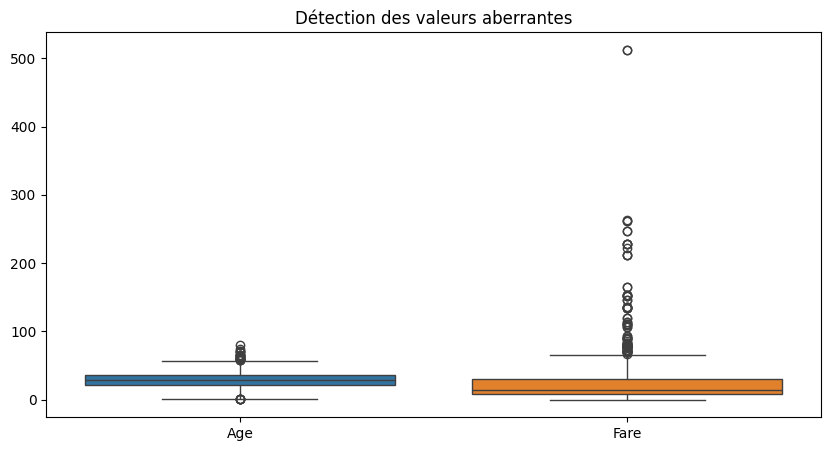

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=X_train[['Age', 'Fare']])
plt.title("Détection des valeurs aberrantes")
plt.show()

In [ ]:
Q1=X_train['Age'].quantile(0.25)
Q3=X_train['Age'].quantile(0.75)

IQR=Q3-Q1

lower=Q1-1.5*IQR
upper=Q3+1.5*IQR

print("Lower:",lower)
print("Upper:",upper)

Lower: 1.0
Upper: 57.0


In [ ]:
outliers_age=X_train[(X_train['Age']<lower)|(X_train['Age']>upper)]
print("Nombre des outliers:",len(outliers_age))

Nombre des outliers: 29


In [ ]:
Q1_fare=X_train['Fare'].quantile(0.25)
Q3_fare=X_train['Fare'].quantile(0.75)

IQR_fare=Q3_fare-Q1_fare

lower_fare=Q1_fare-1.5*IQR_fare
upper_fare=Q3_fare+1.5*IQR_fare

print("Lower Fare:", lower_fare)
print("Upper Fare:", upper_fare)

Lower Fare: -26.7605
Upper Fare: 65.6563


In [ ]:
outliers_fare=X_train[X_train['Fare'] > upper_fare]
print("Nombre des outliers:", len(outliers_fare))

Nombre des outliers: 91


In [ ]:
X_train['Age']=X_train['Age'].clip(
    lower=lower,
    upper=upper
)
X_train['Fare']=X_train['Fare'].clip(
    lower=lower_fare,
    upper=upper_fare
)

In [ ]:
X_test['Age']=X_test['Age'].clip(
    lower=lower,
    upper=upper
)
X_test['Fare']=X_test['Fare'].clip(
    lower=lower_fare,
    upper=upper_fare
)

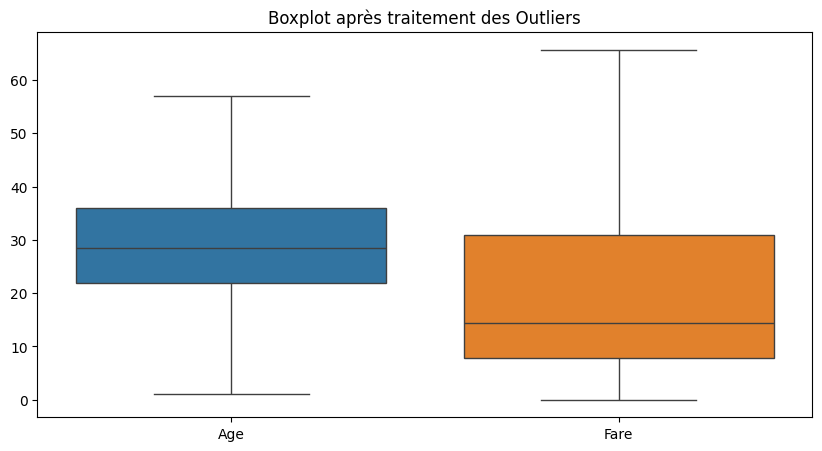

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=X_train[['Age', 'Fare']])
plt.title("Boxplot après traitement des Outliers")
plt.show()

**PARTIE:3**

Encodage des variables catégorielles

In [ ]:
print("Variables catégorielles:")
print(X_train.select_dtypes(include=['object']).columns)

Variables catégorielles:
Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='object')


In [ ]:
print(X_train['Sex'].unique())
print(X_train['Embarked'].unique())

['male' 'female']
['S' 'C' 'Q']


In [ ]:
X_train['Sex'] = X_train['Sex'].map({
    'male': 0,'female': 1
})
X_test['Sex'] = X_test['Sex'].map({
    'male': 0,'female': 1
})

In [ ]:
print(X_train['Sex'].unique())

[0 1]


In [ ]:
X_train = pd.get_dummies(X_train, columns=['Embarked'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['Embarked'], dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [ ]:
print(X_train.head())

     PassengerId  Pclass                                         Name  Sex  \
692          693       3                                 Lam, Mr. Ali    0   
481          482       2             Frost, Mr. Anthony Wood "Archie"    0   
527          528       1                           Farthing, Mr. John    0   
855          856       3                   Aks, Mrs. Sam (Leah Rosen)    1   
801          802       2  Collyer, Mrs. Harvey (Charlotte Annie Tate)    1   

      Age  SibSp  Parch      Ticket     Fare  Embarked_C  Embarked_Q  \
692  28.5      0      0        1601  56.4958           0           0   
481  28.5      0      0      239854   0.0000           0           0   
527  28.5      0      0    PC 17483  65.6563           0           0   
855  18.0      0      1      392091   9.3500           0           0   
801  31.0      1      1  C.A. 31921  26.2500           0           0   

     Embarked_S  
692           1  
481           1  
527           1  
855           1  
801     

In [ ]:
df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)

df[['Name', 'Title']].head(10)

,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr
5,"Moran, Mr. James",Mr
6,"McCarthy, Mr. Timothy J",Mr
7,"Palsson, Master. Gosta Leonard",Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs


In [ ]:
df['Title'].value_counts()

,count
Title,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


Normalisation et Standardisation des données

In [48]:
scaler=MinMaxScaler()

X_train_norm=X_train.copy()
X_test_norm=X_test.copy()

X_train_norm[['Age','Fare']]=scaler.fit_transform(
    X_train[['Age','Fare']]
)

X_test_norm[['Age','Fare']]=scaler.transform(
    X_test[['Age','Fare']]
)


In [51]:
print(X_train_norm[['Age','Fare']].head())

          Age      Fare
692  0.491071  0.860478
481  0.491071  0.000000
527  0.491071  1.000000
855  0.303571  0.142408
801  0.535714  0.399809


In [49]:
standard_scaler=StandardScaler()

X_train_std=X_train.copy()
X_test_std=X_test.copy()
X_train_std[['Age', 'Fare']]=standard_scaler.fit_transform(
    X_train[['Age', 'Fare']]
)

X_test_std[['Age', 'Fare']]=standard_scaler.transform(
    X_test[['Age', 'Fare']]
)

In [50]:
print(X_train_std[['Age','Fare']].head())

          Age      Fare
692 -0.065863  1.587313
481 -0.065863 -1.168780
527 -0.065863  2.034199
855 -0.914811 -0.712650
801  0.136268  0.111801


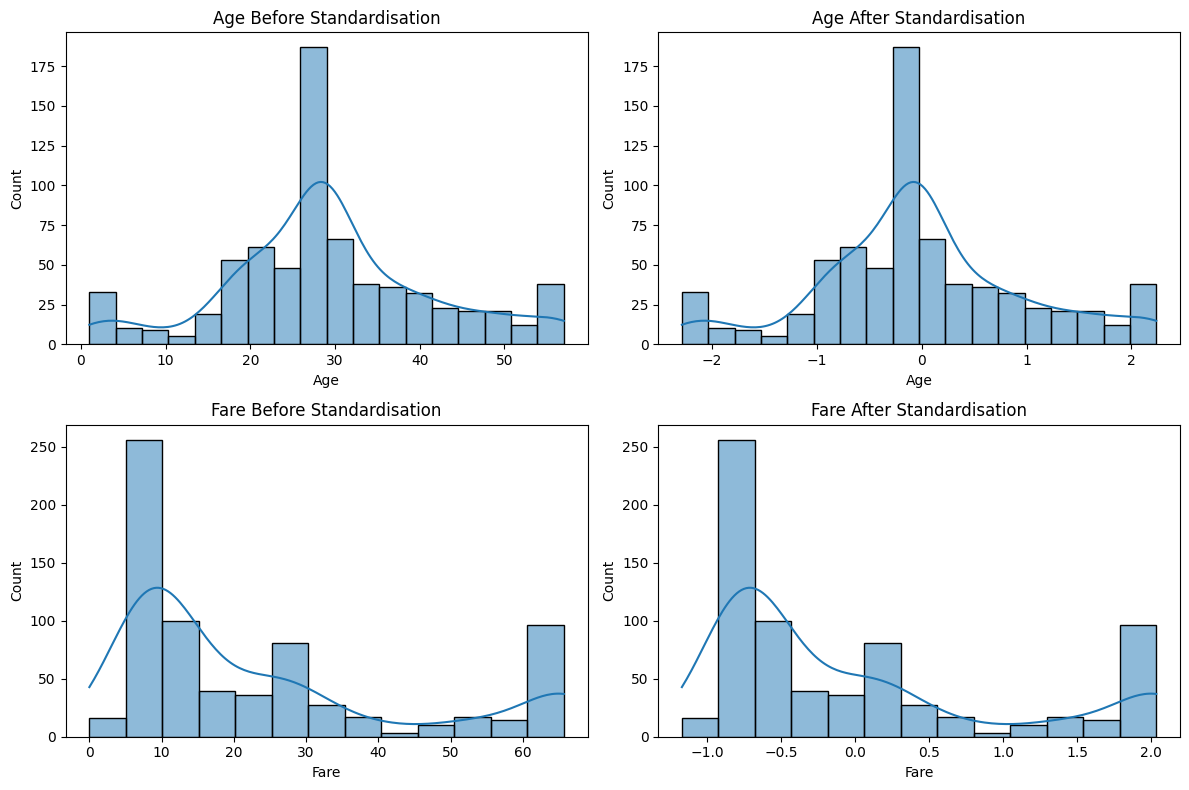

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(X_train['Age'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Age Before Standardisation')

sns.histplot(X_train_std['Age'], kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Age After Standardisation')

sns.histplot(X_train['Fare'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Fare Before Standardisation')

sns.histplot(X_train_std['Fare'], kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Fare After Standardisation')

plt.tight_layout()
plt.show()

In [53]:
print(X_train_std[['Age','Fare']].mean())
print(X_train_std[['Age','Fare']].std())

Age     2.494883e-18
Fare    1.908586e-16
dtype: float64
Age     1.000703
Fare    1.000703
dtype: float64


**Partie 4 :**

In [54]:
print(y_train.value_counts())

Survived
0    439
1    273
Name: count, dtype: int64


In [55]:
print(y_train.value_counts(normalize=True)*100)

Survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64


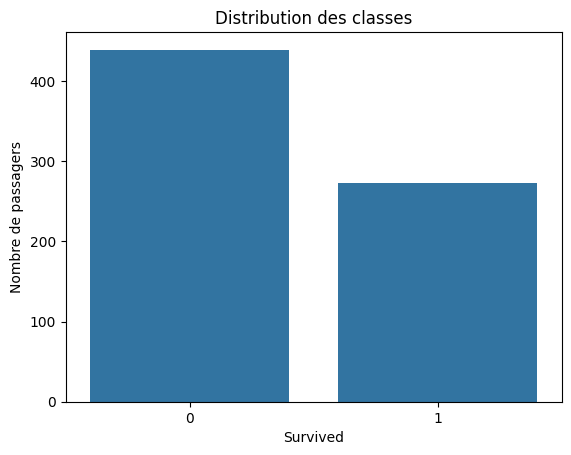

In [56]:
sns.countplot(x=y_train)

plt.title("Distribution des classes")
plt.xlabel("Survived")
plt.ylabel("Nombre de passagers")

plt.show()

Gestion du déséquilibre

In [58]:
from imblearn.under_sampling import RandomUnderSampler

under=RandomUnderSampler(random_state=42)

X_train_under,y_train_under=under.fit_resample(X_train, y_train)

In [59]:
print(y_train_under.value_counts())

Survived
0    273
1    273
Name: count, dtype: int64


In [66]:
from imblearn.over_sampling import SMOTE

smote=SMOTE(random_state=42)

X_train_smote,y_train_smote=smote.fit_resample(
    X_train_smote_input, y_train
)

In [61]:
print(X_train.select_dtypes(include='object').columns)

Index(['Name', 'Ticket'], dtype='object')


In [62]:
X_train_smote_input=X_train.drop(columns=['Name','Ticket'])

In [63]:
X_test_input=X_test.drop(columns=['Name','Ticket'])

In [67]:
from imblearn.over_sampling import SMOTE

smote=SMOTE(random_state=42)

X_train_smote,y_train_smote=smote.fit_resample(
    X_train_smote_input, y_train
)

In [68]:
print(y_train_smote.value_counts())

Survived
1    439
0    439
Name: count, dtype: int64
